# Payment Behaviour & Digital Payment Intelligence

**Fundamentals of Machine Learning | Problem Statement 7**

This notebook implements a complete unsupervised learning workflow: data inspection, cleaning, customer-level feature engineering, EDA, scaling, K-Means and agglomerative clustering, internal validation, PCA visualization, cluster profiling, and industry recommendations.

**Data integrity note:** `payment_transactions_synthetic.csv` is a reproducible synthetic dataset built for this assignment. It is not real customer, bank, UPI, card-network, or wallet data. Segment descriptions are hypotheses to validate with genuine operational data before business use.

## 1. Import libraries and configure outputs

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
DATA_PATH = Path('payment_transactions_synthetic.csv')
PLOT_DIR = Path('plots')
OUTPUT_DIR = Path('outputs')
PLOT_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)
plt.rcParams.update({'figure.figsize': (8, 5), 'axes.spines.top': False, 'axes.spines.right': False})


## 2. Load and inspect the data

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print('Raw shape:', df_raw.shape)
display(df_raw.head())
display(df_raw.tail())
print('Data types:')
display(df_raw.dtypes.to_frame('dtype'))
print('Descriptive statistics:')
display(df_raw.describe(include='all').T)
print('Duplicate transaction IDs:', df_raw['transaction_id'].duplicated().sum())
print('Missing values:')
display(df_raw.isna().sum().sort_values(ascending=False).to_frame('missing_count'))


Raw shape: (7535, 13)


,transaction_id,customer_id,transaction_date,transaction_amount_inr,payment_mode,channel,merchant_category,cashback_used,cashback_amount_inr,discount_pct,promo_applied,promo_type,emi_tenure_months
0,T0000001,C00001,2025-09-14,148.87,Cash,Physical Store,Groceries,0,0.00,9.38,1,Bank Offer,0
1,T0000002,C00001,2025-09-25,186.78,UPI,Mobile App,Electronics,1,2.07,14.34,1,Coupon,0
2,T0000003,C00001,2025-01-12,2635.79,Digital Wallet,Mobile App,Dining,1,34.26,23.07,1,Coupon,0
3,T0000004,C00001,2025-11-10,149.78,UPI,Physical Store,Dining,1,8.93,11.71,1,Bank Offer,0
4,T0000005,C00001,2025-06-15,164.67,Digital Wallet,Mobile App,Pharmacy,1,9.57,20.84,1,Coupon,0


,transaction_id,customer_id,transaction_date,transaction_amount_inr,payment_mode,channel,merchant_category,cashback_used,cashback_amount_inr,discount_pct,promo_applied,promo_type,emi_tenure_months
7530,T0006335,C00613,2025-05-20,547.69,Card,Website,Groceries,0,0.0,1.17,0,NaN,0
7531,T0002424,C00236,2025-03-29,2312.99,UPI,Website,Groceries,0,0.0,0.16,0,NaN,0
7532,T0001967,C00193,2025-01-29,216.07,Card,Mobile App,Dining,0,0.0,0.03,0,NaN,0
7533,T0001871,C00180,2025-03-15,179.83,UPI,Website,Groceries,0,0.0,0.08,0,NaN,0
7534,T0005286,C00507,2025-02-12,332.83,UPI,Mobile App,Apparel,0,0.0,9.06,1,Cashback Offer,0


Data types:


,dtype
transaction_id,object
customer_id,object
transaction_date,object
transaction_amount_inr,float64
payment_mode,object
channel,object
merchant_category,object
cashback_used,int64
cashback_amount_inr,float64
discount_pct,float64


Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,7535,7491,T0002837,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,7535,720,C00681,29,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_date,7535,365,2025-05-09,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_amount_inr,7505.0,NaN,NaN,NaN,1457.356414,3586.295229,-382.64,265.43,492.8,1075.51,175828.71
payment_mode,7445,5,UPI,2188,NaN,NaN,NaN,NaN,NaN,NaN,NaN
channel,7535,3,Mobile App,3169,NaN,NaN,NaN,NaN,NaN,NaN,NaN
merchant_category,7490,7,Groceries,1607,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cashback_used,7535.0,NaN,NaN,NaN,0.31785,0.465672,0.0,0.0,0.0,1.0,1.0
cashback_amount_inr,7475.0,NaN,NaN,NaN,12.858532,39.009018,0.0,0.0,0.0,7.695,250.0
discount_pct,7535.0,NaN,NaN,NaN,6.564576,8.469075,0.0,0.45,1.45,11.805,38.86


Duplicate transaction IDs: 44
Missing values:


,missing_count
promo_type,4465
payment_mode,90
cashback_amount_inr,60
merchant_category,45
transaction_amount_inr,30
customer_id,0
transaction_date,0
transaction_id,0
channel,0
cashback_used,0


## 3. Data cleaning and outlier treatment
Duplicate transaction IDs are removed. Invalid non-positive purchase values are excluded because they cannot represent ordinary completed purchases in this sample. Missing amounts are median-imputed; missing payment mode and category use the training/sample mode. Remaining missing cashback amounts are filled with zero where not recorded. Plausibly high positive amounts are retained but capped at the 99.5th percentile to limit the influence of synthetic extreme outliers. In a production system, reversals/refunds should be explicitly labeled rather than automatically discarded.

In [3]:
df = df_raw.copy()
df['transaction_date'] = pd.to_datetime(df['transaction_date'], errors='coerce')
missing_before = df.isna().sum().sort_values(ascending=False)

before_rows = len(df)
df = df.drop_duplicates(subset='transaction_id', keep='first').copy()
after_dedup_rows = len(df)
df['transaction_amount_inr'] = pd.to_numeric(df['transaction_amount_inr'], errors='coerce')
invalid_amount_count = int((df['transaction_amount_inr'] <= 0).sum())
df = df.loc[df['transaction_amount_inr'].isna() | (df['transaction_amount_inr'] > 0)].copy()
amount_median = df['transaction_amount_inr'].median()
df['transaction_amount_inr'] = df['transaction_amount_inr'].fillna(amount_median)
df['payment_mode'] = df['payment_mode'].fillna(df['payment_mode'].mode().iloc[0])
df['merchant_category'] = df['merchant_category'].fillna(df['merchant_category'].mode().iloc[0])
df['channel'] = df['channel'].fillna(df['channel'].mode().iloc[0])
df['promo_type'] = df['promo_type'].fillna('None')
df['cashback_used'] = df['cashback_used'].fillna(0).astype(int)
df['cashback_amount_inr'] = df['cashback_amount_inr'].fillna(0).clip(lower=0)
df['discount_pct'] = df['discount_pct'].fillna(df['discount_pct'].median()).clip(0, 100)
df['promo_applied'] = df['promo_applied'].fillna(0).astype(int)
df['emi_tenure_months'] = df['emi_tenure_months'].fillna(0).astype(int)
upper_cap = float(df['transaction_amount_inr'].quantile(0.995))
num_capped = int((df['transaction_amount_inr'] > upper_cap).sum())
df['transaction_amount_inr'] = df['transaction_amount_inr'].clip(upper=upper_cap)
df = df.dropna(subset=['customer_id', 'transaction_date']).copy()

cleaning_summary = pd.DataFrame({
    'Metric': ['Raw rows', 'Rows after duplicate removal', 'Duplicate transaction IDs removed', 'Invalid non-positive amounts excluded', 'Remaining cleaned rows', 'Missing amounts imputed', 'Positive amount values capped at 99.5th percentile', 'Amount cap (INR)'],
    'Value': [before_rows, after_dedup_rows, before_rows-after_dedup_rows, invalid_amount_count, len(df), int(df_raw['transaction_amount_inr'].isna().sum()), num_capped, round(upper_cap, 2)]
})
display(cleaning_summary)
print('Remaining missing values:', int(df.isna().sum().sum()))
df.to_csv(OUTPUT_DIR/'cleaned_transactions.csv', index=False)


,Metric,Value
0,Raw rows,7535.00
1,Rows after duplicate removal,7491.00
2,Duplicate transaction IDs removed,44.00
3,Invalid non-positive amounts excluded,28.00
4,Remaining cleaned rows,7463.00
5,Missing amounts imputed,30.00
6,Positive amount values capped at 99.5th percen...,38.00
7,Amount cap (INR),18875.11


Remaining missing values: 0


## 4. Exploratory data analysis (EDA)

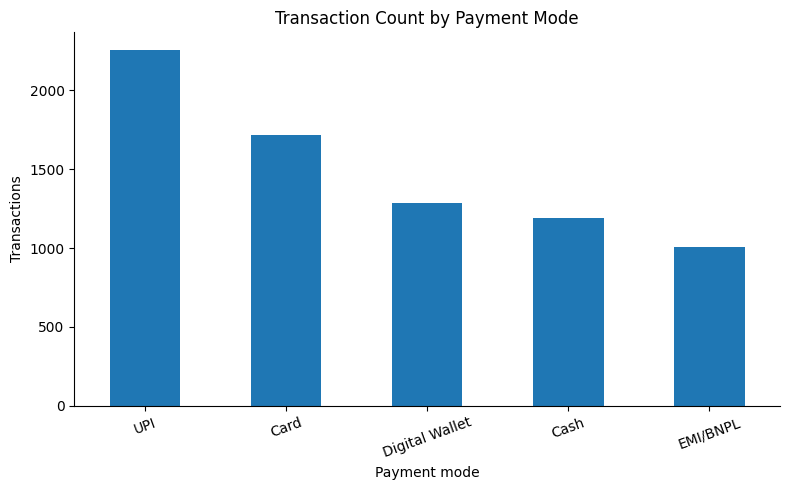

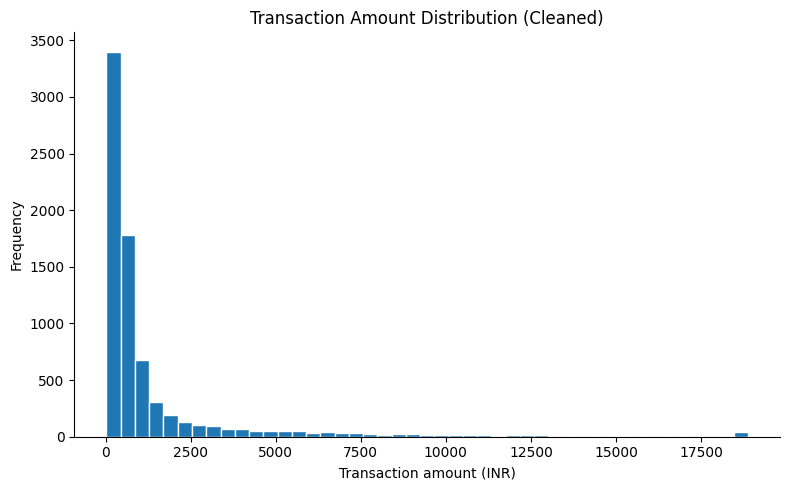

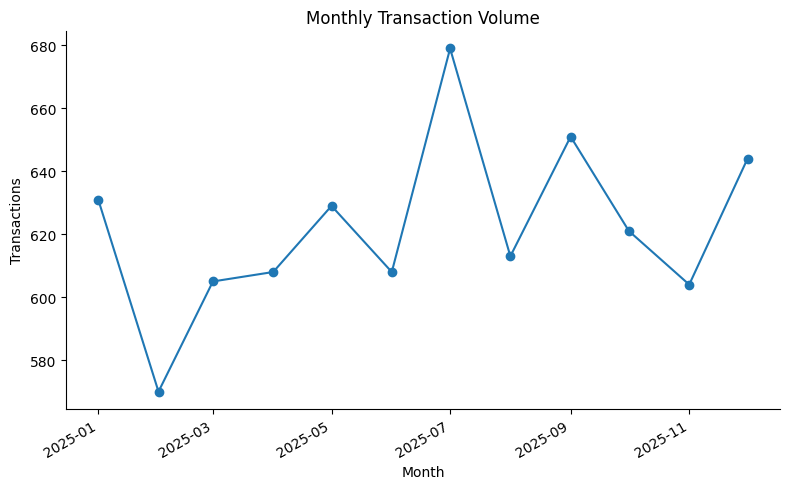

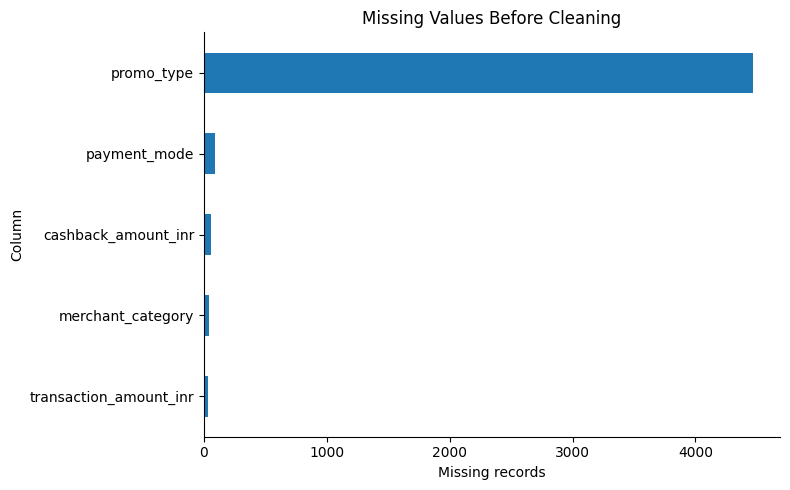

Cleaned transaction count: 7463
Unique customers: 720
Date range: 2025-01-01 to 2025-12-31
Mean transaction amount (INR): 1394.69


In [4]:
# Payment method usage
mode_counts = df['payment_mode'].value_counts().reindex(['UPI','Card','Digital Wallet','Cash','EMI/BNPL']).dropna()
fig, ax = plt.subplots()
mode_counts.plot(kind='bar', ax=ax)
ax.set_title('Transaction Count by Payment Mode')
ax.set_xlabel('Payment mode'); ax.set_ylabel('Transactions'); ax.tick_params(axis='x', rotation=20)
fig.tight_layout(); fig.savefig(PLOT_DIR/'payment_mode_distribution.png', dpi=180); fig.savefig(PLOT_DIR/'payment_mode_distribution.jpg', dpi=180); plt.show()

# Distribution of transaction amounts
fig, ax = plt.subplots()
ax.hist(df['transaction_amount_inr'], bins=45, edgecolor='white')
ax.set_title('Transaction Amount Distribution (Cleaned)')
ax.set_xlabel('Transaction amount (INR)'); ax.set_ylabel('Frequency')
fig.tight_layout(); fig.savefig(PLOT_DIR/'transaction_amount_distribution.png', dpi=180); fig.savefig(PLOT_DIR/'transaction_amount_distribution.jpg', dpi=180); plt.show()

# Monthly activity
monthly = df.set_index('transaction_date').resample('MS').agg(transaction_count=('transaction_id','count'), total_value=('transaction_amount_inr','sum'))
fig, ax = plt.subplots()
ax.plot(monthly.index, monthly['transaction_count'], marker='o')
ax.set_title('Monthly Transaction Volume')
ax.set_xlabel('Month'); ax.set_ylabel('Transactions')
fig.autofmt_xdate(); fig.tight_layout(); fig.savefig(PLOT_DIR/'monthly_transaction_volume.png', dpi=180); fig.savefig(PLOT_DIR/'monthly_transaction_volume.jpg', dpi=180); plt.show()

# Missingness recorded before data cleaning
missing_plot = missing_before[missing_before > 0].sort_values()
fig, ax = plt.subplots()
if len(missing_plot):
    missing_plot.plot(kind='barh', ax=ax)
    ax.set_title('Missing Values Before Cleaning'); ax.set_xlabel('Missing records'); ax.set_ylabel('Column')
else:
    ax.text(0.5, 0.5, 'No missing values detected', ha='center', va='center')
fig.tight_layout(); fig.savefig(PLOT_DIR/'missing_values_before_cleaning.png', dpi=180); fig.savefig(PLOT_DIR/'missing_values_before_cleaning.jpg', dpi=180); plt.show()

print('Cleaned transaction count:', len(df))
print('Unique customers:', df['customer_id'].nunique())
print('Date range:', df['transaction_date'].min().date(), 'to', df['transaction_date'].max().date())
print('Mean transaction amount (INR):', round(df['transaction_amount_inr'].mean(), 2))


## 5. Customer-level feature engineering
Each customer becomes one observation. Payment shares are more informative than a single dominant-mode label because customers can use multiple payment methods. The combined feature set adds log spending, transaction frequency, cashback/discount behavior, EMI share, channel shares, and category diversity. We use all customers because this is a descriptive unsupervised task, not a supervised future-outcome prediction task; no conventional train/test split is required for the clustering analysis.

In [5]:
mode_share = pd.crosstab(df['customer_id'], df['payment_mode'], normalize='index')
mode_share = mode_share.reindex(columns=['UPI','Card','Digital Wallet','Cash','EMI/BNPL'], fill_value=0)
mode_share.columns = ['share_upi','share_card','share_wallet','share_cash','share_emi_bnpl']
channel_share = pd.crosstab(df['customer_id'], df['channel'], normalize='index')
channel_share = channel_share.reindex(columns=['Mobile App','Website','Physical Store'], fill_value=0)
channel_share.columns = ['share_mobile_app','share_website','share_physical_store']

cust = df.groupby('customer_id').agg(
    n_transactions=('transaction_id','count'),
    total_spend_inr=('transaction_amount_inr','sum'),
    avg_transaction_value_inr=('transaction_amount_inr','mean'),
    median_transaction_value_inr=('transaction_amount_inr','median'),
    transaction_value_std_inr=('transaction_amount_inr','std'),
    cashback_usage_rate=('cashback_used','mean'),
    average_discount_pct=('discount_pct','mean'),
    promo_response_rate=('promo_applied','mean'),
    average_cashback_inr=('cashback_amount_inr','mean'),
    category_diversity=('merchant_category','nunique'),
    first_transaction=('transaction_date','min'),
    last_transaction=('transaction_date','max'),
).fillna({'transaction_value_std_inr':0})
cust['active_months'] = df.groupby('customer_id')['transaction_date'].apply(lambda s: max(1, s.dt.to_period('M').nunique()))
cust['emi_usage_rate'] = df.assign(is_emi=(df['payment_mode']=='EMI/BNPL').astype(int)).groupby('customer_id')['is_emi'].mean()
cust = cust.join(mode_share).join(channel_share)
cust['transactions_per_active_month'] = cust['n_transactions'] / cust['active_months']
cust['log_total_spend'] = np.log1p(cust['total_spend_inr'])
cust['log_average_transaction_value'] = np.log1p(cust['avg_transaction_value_inr'])
cust = cust.reset_index()

mode_features = ['share_upi','share_card','share_wallet','share_cash','share_emi_bnpl']
combined_features = mode_features + [
    'log_total_spend','log_average_transaction_value','n_transactions',
    'transactions_per_active_month','cashback_usage_rate','average_discount_pct',
    'promo_response_rate','emi_usage_rate','share_mobile_app','share_website',
    'share_physical_store','category_diversity'
]
cust.to_csv('customer_payment_features.csv', index=False)
cust.to_csv(OUTPUT_DIR/'customer_payment_features.csv', index=False)
print('Customer-level feature matrix:', cust.shape)
display(cust.head())
print('Payment-mode share features:', mode_features)
print('Combined feature count:', len(combined_features))


Customer-level feature matrix: (720, 26)


,customer_id,n_transactions,total_spend_inr,avg_transaction_value_inr,median_transaction_value_inr,transaction_value_std_inr,cashback_usage_rate,average_discount_pct,promo_response_rate,average_cashback_inr,category_diversity,first_transaction,last_transaction,active_months,emi_usage_rate,share_upi,share_card,share_wallet,share_cash,share_emi_bnpl,share_mobile_app,share_website,share_physical_store,transactions_per_active_month,log_total_spend,log_average_transaction_value
0,C00001,13,6959.64,535.356923,253.140,673.325364,0.769231,10.975385,0.846154,11.603846,6,2025-01-01,2025-12-04,6,0.000000,0.230769,0.076923,0.615385,0.076923,0.000000,0.461538,0.230769,0.307692,2.166667,8.848027,6.284800
1,C00002,17,5703.00,335.470588,302.680,249.291937,0.117647,8.168235,0.470588,1.260588,6,2025-01-18,2025-12-27,7,0.000000,0.588235,0.058824,0.235294,0.117647,0.000000,0.588235,0.235294,0.176471,2.428571,8.648923,5.818511
2,C00003,16,15865.12,991.570000,353.095,2057.060175,0.312500,5.292500,0.375000,16.125625,5,2025-01-27,2025-12-11,8,0.062500,0.562500,0.187500,0.125000,0.062500,0.062500,0.437500,0.312500,0.250000,2.000000,9.671941,6.900298
3,C00004,5,2637.61,527.522000,539.050,189.303105,0.600000,2.102000,0.400000,8.808000,3,2025-08-05,2025-11-11,3,0.000000,0.800000,0.200000,0.000000,0.000000,0.000000,0.600000,0.200000,0.200000,1.666667,7.878008,6.270084
4,C00005,9,15200.16,1688.906667,1625.670,936.219898,0.000000,3.273333,0.222222,0.000000,4,2025-01-12,2025-10-19,7,0.111111,0.000000,0.888889,0.000000,0.000000,0.111111,0.333333,0.333333,0.333333,1.285714,9.629127,7.432429


Payment-mode share features: ['share_upi', 'share_card', 'share_wallet', 'share_cash', 'share_emi_bnpl']
Combined feature count: 17


## 6. Standardize features and select the number of clusters
Distance-based clustering is sensitive to variable scale. Continuous and share features are standardized before modeling. Elbow/inertia shows within-cluster sum of squares; silhouette (higher is better, roughly -1 to 1) and Davies-Bouldin (lower is better) provide complementary internal checks. These metrics assess geometric compactness/separation, not business value by themselves.

,k,inertia,silhouette,davies_bouldin
0,2,9882.5966,0.2272,1.4353
1,3,7678.0094,0.2571,1.4874
2,4,6345.5287,0.2757,1.3465
3,5,5528.5291,0.2821,1.3577
4,6,5140.7673,0.2510,1.4708
5,7,4839.0852,0.2404,1.5655
6,8,4624.1197,0.2233,1.6389


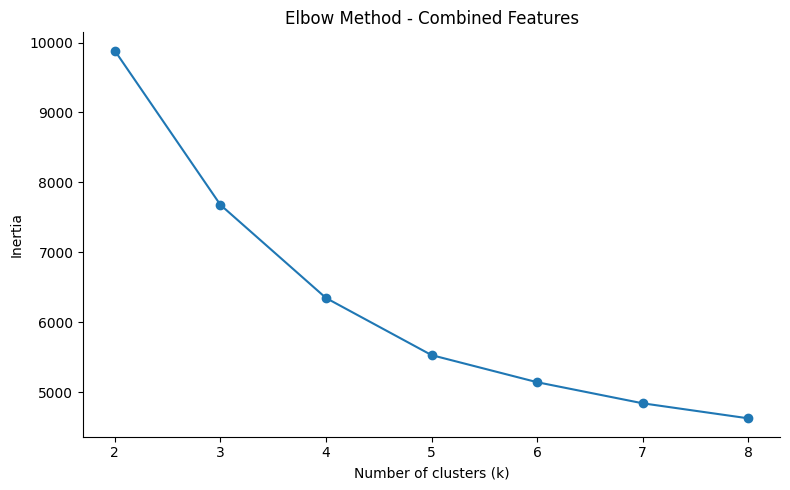

In [6]:
scaler_mode = StandardScaler()
X_mode = scaler_mode.fit_transform(cust[mode_features])
scaler_combined = StandardScaler()
X_combined = scaler_combined.fit_transform(cust[combined_features])

k_values = range(2, 9)
elbow_rows = []
for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = km.fit_predict(X_combined)
    elbow_rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(X_combined, labels), 'davies_bouldin': davies_bouldin_score(X_combined, labels)})
elbow_results = pd.DataFrame(elbow_rows)
display(elbow_results.round(4))
elbow_results.to_csv(OUTPUT_DIR/'kmeans_k_selection.csv', index=False)

fig, ax = plt.subplots()
ax.plot(elbow_results['k'], elbow_results['inertia'], marker='o')
ax.set_title('Elbow Method - Combined Features'); ax.set_xlabel('Number of clusters (k)'); ax.set_ylabel('Inertia')
fig.tight_layout(); fig.savefig(PLOT_DIR/'elbow_curve.png', dpi=180); fig.savefig(PLOT_DIR/'elbow_curve.jpg', dpi=180); plt.show()


## 7. Compare K-Means and hierarchical clustering
The comparison evaluates both feature designs at multiple values of k. Agglomerative clustering uses Ward linkage; unlike K-Means, it builds a hierarchy by progressively merging observations. We use the same standardized feature matrix and internal metrics for an apples-to-apples descriptive comparison. A practical final choice should balance separation, stability, cluster size, and interpretability.

,feature_set,algorithm,k,inertia,silhouette,davies_bouldin
15,Payment + spending + frequency + offers,Agglomerative (Ward),2,NaN,0.2270,1.2991
14,Payment + spending + frequency + offers,K-Means,2,9882.5966,0.2272,1.4353
17,Payment + spending + frequency + offers,Agglomerative (Ward),3,NaN,0.2530,1.5148
16,Payment + spending + frequency + offers,K-Means,3,7678.0094,0.2571,1.4874
19,Payment + spending + frequency + offers,Agglomerative (Ward),4,NaN,0.2711,1.3809
18,Payment + spending + frequency + offers,K-Means,4,6345.5287,0.2757,1.3465
21,Payment + spending + frequency + offers,Agglomerative (Ward),5,NaN,0.2717,1.4146
20,Payment + spending + frequency + offers,K-Means,5,5528.5291,0.2821,1.3577
23,Payment + spending + frequency + offers,Agglomerative (Ward),6,NaN,0.2340,1.5434
22,Payment + spending + frequency + offers,K-Means,6,5140.7673,0.2510,1.4708


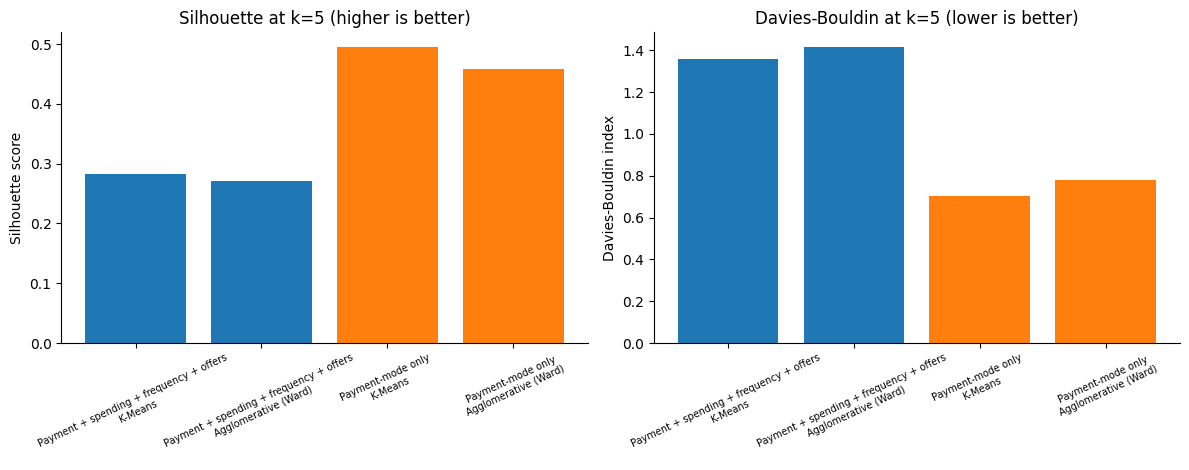

In [7]:
comparison_rows = []
for feature_name, X in [('Payment-mode only', X_mode), ('Payment + spending + frequency + offers', X_combined)]:
    for k in range(2, 9):
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
        labels_km = km.fit_predict(X)
        comparison_rows.append({'feature_set': feature_name, 'algorithm':'K-Means', 'k':k,
                                'inertia':km.inertia_, 'silhouette':silhouette_score(X, labels_km),
                                'davies_bouldin':davies_bouldin_score(X, labels_km)})
        agg = AgglomerativeClustering(n_clusters=k, linkage='ward')
        labels_agg = agg.fit_predict(X)
        comparison_rows.append({'feature_set': feature_name, 'algorithm':'Agglomerative (Ward)', 'k':k,
                                'inertia':np.nan, 'silhouette':silhouette_score(X, labels_agg),
                                'davies_bouldin':davies_bouldin_score(X, labels_agg)})
model_comparison = pd.DataFrame(comparison_rows)
model_comparison.to_csv('model_comparison.csv', index=False)
model_comparison.to_csv(OUTPUT_DIR/'model_comparison.csv', index=False)
display(model_comparison.sort_values(['feature_set','k','algorithm']).round(4))

# Compare feature sets and algorithms at the selected business-readable k = 5.
selected_k = 5
selected_compare = model_comparison[model_comparison['k']==selected_k].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for feature_set, grp in selected_compare.groupby('feature_set'):
    axes[0].bar([f"{feature_set}\n{a}" for a in grp['algorithm']], grp['silhouette'], label=feature_set)
    axes[1].bar([f"{feature_set}\n{a}" for a in grp['algorithm']], grp['davies_bouldin'], label=feature_set)
axes[0].set_title('Silhouette at k=5 (higher is better)'); axes[0].set_ylabel('Silhouette score')
axes[1].set_title('Davies-Bouldin at k=5 (lower is better)'); axes[1].set_ylabel('Davies-Bouldin index')
for ax in axes: ax.tick_params(axis='x', labelrotation=25, labelsize=7)
fig.tight_layout(); fig.savefig(PLOT_DIR/'model_comparison_k5.png', dpi=180); fig.savefig(PLOT_DIR/'model_comparison_k5.jpg', dpi=180); plt.show()


## 7.1. Hierarchical clustering structure
A truncated Ward dendrogram on a reproducible subsample shows how customers merge at increasing distances. The plot is for structure interpretation; final metrics are computed on all customers.

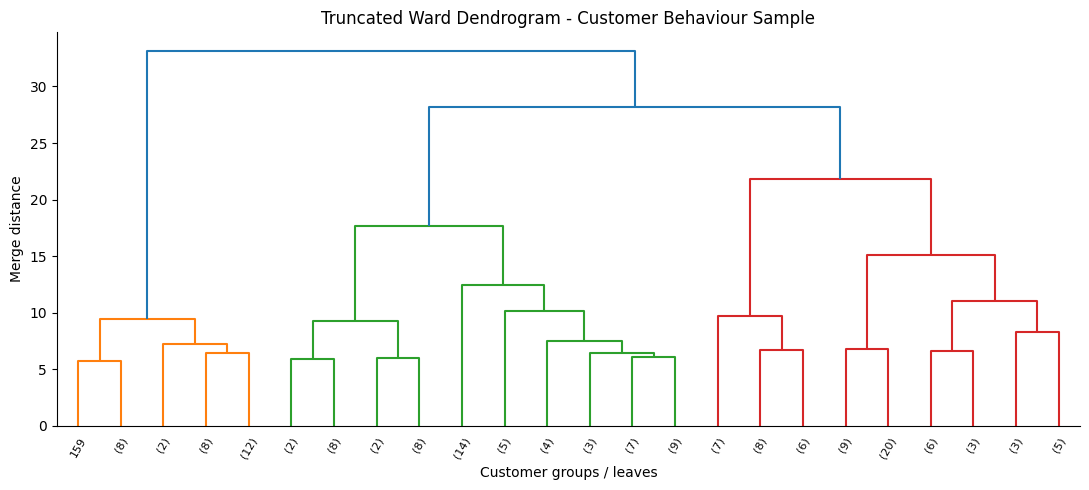

In [8]:
sample_size = min(160, len(cust))
sample_idx = np.random.default_rng(RANDOM_STATE).choice(len(cust), size=sample_size, replace=False)
Z = linkage(X_combined[sample_idx], method='ward')
fig, ax = plt.subplots(figsize=(11, 5))
dendrogram(Z, truncate_mode='lastp', p=24, show_leaf_counts=True, leaf_rotation=60, leaf_font_size=8, ax=ax)
ax.set_title('Truncated Ward Dendrogram - Customer Behaviour Sample')
ax.set_xlabel('Customer groups / leaves'); ax.set_ylabel('Merge distance')
fig.tight_layout(); fig.savefig(PLOT_DIR/'hierarchical_dendrogram.png', dpi=180); fig.savefig(PLOT_DIR/'hierarchical_dendrogram.jpg', dpi=180); plt.show()


## 8. Fit the final customer segmentation
A five-segment solution is used for the main profile because it gives the report actionable payment-oriented groups to compare. The selection should be reviewed against the elbow curve and metric table rather than treating k=5 as universally optimal. Numeric cluster IDs are arbitrary; labels are assigned post hoc from each cluster's dominant payment share.

,cluster,customer_count,n_transactions,total_spend_inr,avg_transaction_value_inr,cashback_usage_rate,average_discount_pct,promo_response_rate,emi_usage_rate,share_upi,share_card,share_wallet,share_cash,share_emi_bnpl,share_mobile_app,share_website,share_physical_store,category_diversity,customer_pct,dominant_mode_feature,segment_name
0,0,221,11.176,9122.125,802.759,0.275,5.613,0.346,0.059,0.637,0.114,0.093,0.096,0.059,0.569,0.157,0.274,4.805,30.694,share_upi,UPI-centric customers
1,1,117,13.385,13459.207,973.530,0.769,11.810,0.786,0.099,0.181,0.103,0.538,0.080,0.099,0.652,0.158,0.190,5.581,16.250,share_wallet,Wallet/offer-oriented customers
2,2,123,7.837,4114.020,526.274,0.027,2.909,0.144,0.033,0.106,0.112,0.046,0.703,0.033,0.114,0.035,0.851,4.089,17.083,share_cash,Cash-oriented customers
3,3,172,10.372,18626.630,1739.762,0.191,5.014,0.297,0.161,0.131,0.562,0.089,0.058,0.161,0.250,0.370,0.380,4.901,23.889,share_card,Card-oriented customers
4,4,87,7.805,35724.357,4753.925,0.241,6.661,0.421,0.566,0.114,0.253,0.032,0.036,0.566,0.265,0.323,0.412,4.011,12.083,share_emi_bnpl,EMI/BNPL-oriented customers


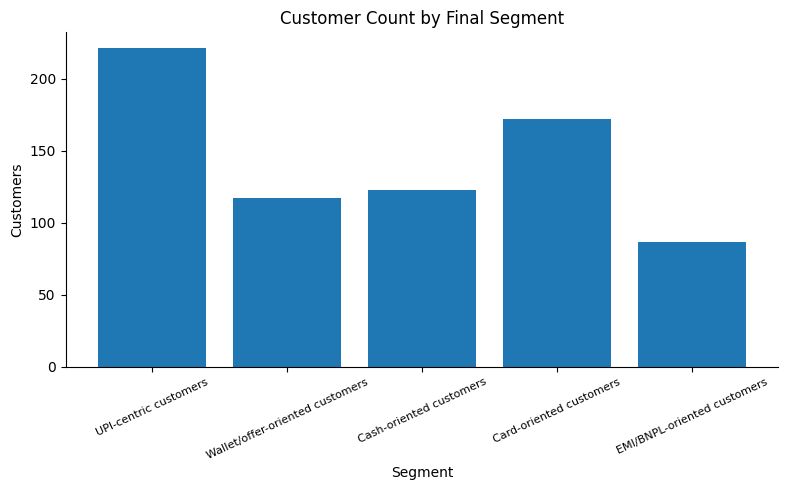

In [9]:
selected_k = 5
final_model = KMeans(n_clusters=selected_k, random_state=RANDOM_STATE, n_init=30)
cust['cluster'] = final_model.fit_predict(X_combined)

profile_cols = ['n_transactions','total_spend_inr','avg_transaction_value_inr','cashback_usage_rate',
                'average_discount_pct','promo_response_rate','emi_usage_rate','share_upi','share_card',
                'share_wallet','share_cash','share_emi_bnpl','share_mobile_app','share_website',
                'share_physical_store','category_diversity']
cluster_profiles = cust.groupby('cluster').agg(customer_count=('customer_id','count'), **{col:(col,'mean') for col in profile_cols}).reset_index()
cluster_profiles['customer_pct'] = 100*cluster_profiles['customer_count']/len(cust)
mode_share_columns = ['share_upi','share_card','share_wallet','share_cash','share_emi_bnpl']
mode_names_by_feature = {'share_upi':'UPI-centric customers','share_card':'Card-oriented customers',
                         'share_wallet':'Wallet/offer-oriented customers','share_cash':'Cash-oriented customers',
                         'share_emi_bnpl':'EMI/BNPL-oriented customers'}
cluster_profiles['dominant_mode_feature'] = cluster_profiles[mode_share_columns].idxmax(axis=1)
cluster_profiles['segment_name'] = cluster_profiles['dominant_mode_feature'].map(mode_names_by_feature)
cluster_profiles.to_csv('cluster_profiles.csv', index=False)
cluster_profiles.to_csv(OUTPUT_DIR/'cluster_profiles.csv', index=False)
# Keep cluster labels and key attributes in an easy-to-review CSV.
cust.to_csv('customer_payment_features.csv', index=False)
cust.to_csv(OUTPUT_DIR/'customer_payment_features.csv', index=False)
display(cluster_profiles.round(3))

fig, ax = plt.subplots()
ax.bar(cluster_profiles['segment_name'], cluster_profiles['customer_count'])
ax.set_title('Customer Count by Final Segment'); ax.set_xlabel('Segment'); ax.set_ylabel('Customers')
ax.tick_params(axis='x', rotation=25, labelsize=8)
fig.tight_layout(); fig.savefig(PLOT_DIR/'cluster_size_distribution.png', dpi=180); fig.savefig(PLOT_DIR/'cluster_size_distribution.jpg', dpi=180); plt.show()


## 9. PCA visualization and cluster profile heatmap
PCA projects the standardized feature matrix into two components for visualization. This is a descriptive projection and may hide separation present in higher dimensions. The heatmap shows cluster-average standardized features to reveal differences across segments.

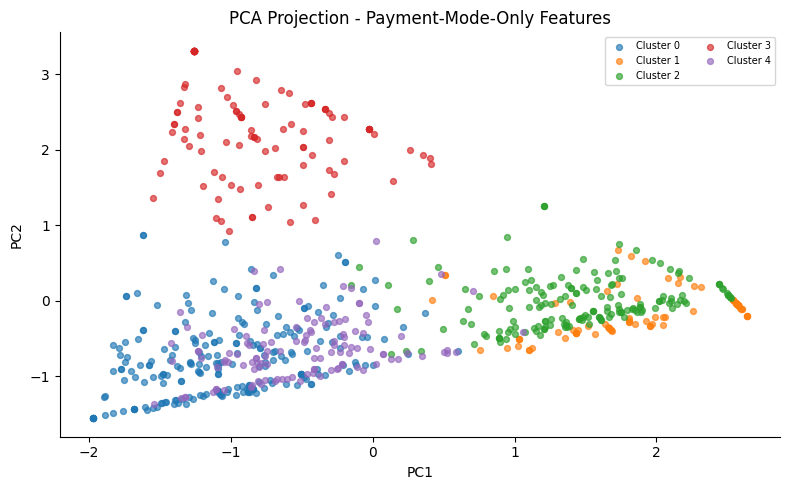

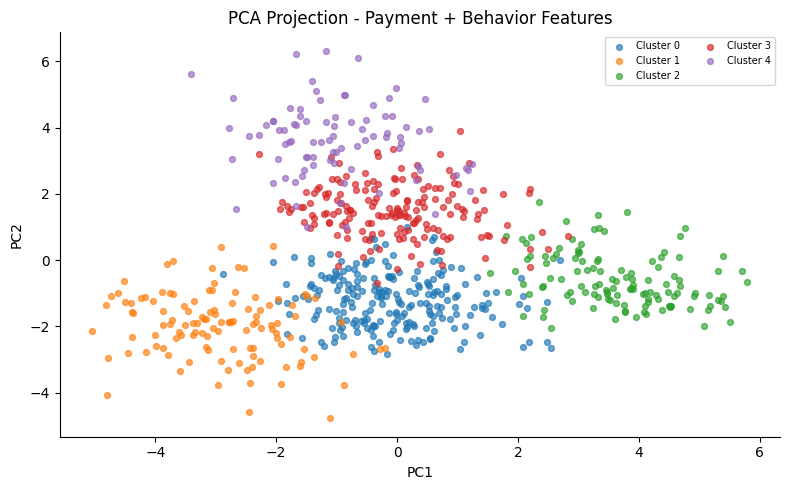

Payment-only PCA explained variance: [0.329 0.265] total= 0.594
Combined PCA explained variance: [0.281 0.237] total= 0.519


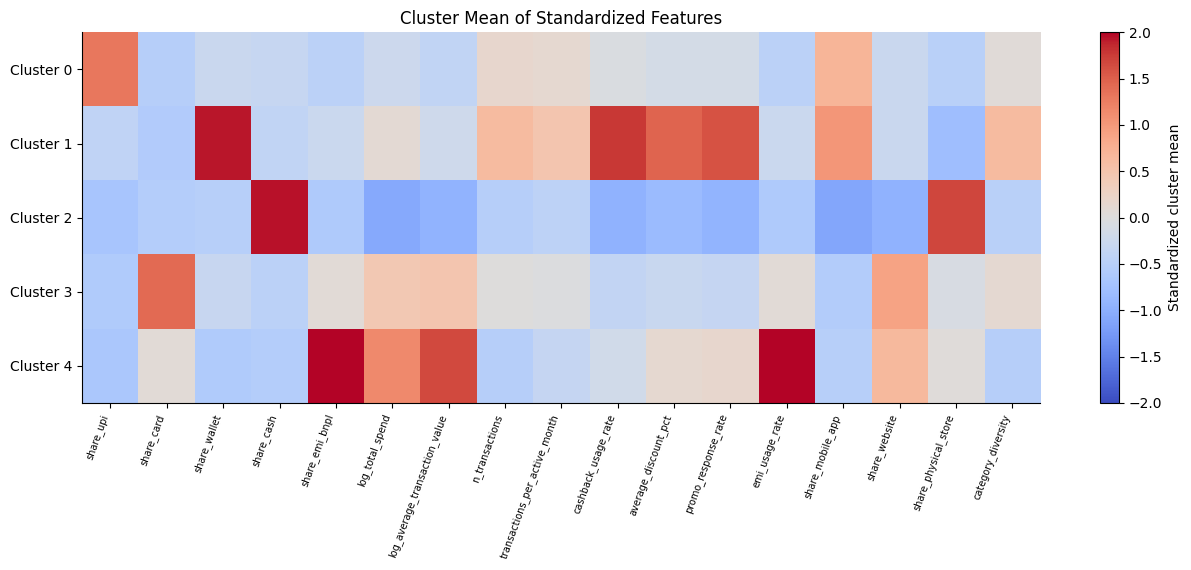

In [10]:
pca_mode = PCA(n_components=2, random_state=RANDOM_STATE)
mode_xy = pca_mode.fit_transform(X_mode)
labels_mode = KMeans(n_clusters=selected_k, random_state=RANDOM_STATE, n_init=30).fit_predict(X_mode)
fig, ax = plt.subplots()
for cl in np.unique(labels_mode):
    mask = labels_mode == cl
    ax.scatter(mode_xy[mask,0], mode_xy[mask,1], s=18, alpha=0.65, label=f'Cluster {cl}')
ax.set_title('PCA Projection - Payment-Mode-Only Features'); ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend(fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(PLOT_DIR/'pca_payment_only.png', dpi=180); fig.savefig(PLOT_DIR/'pca_payment_only.jpg', dpi=180); plt.show()

pca_combined = PCA(n_components=2, random_state=RANDOM_STATE)
combined_xy = pca_combined.fit_transform(X_combined)
fig, ax = plt.subplots()
for cl in np.unique(cust['cluster']):
    mask = cust['cluster'].to_numpy() == cl
    ax.scatter(combined_xy[mask,0], combined_xy[mask,1], s=18, alpha=0.65, label=f'Cluster {cl}')
ax.set_title('PCA Projection - Payment + Behavior Features'); ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend(fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(PLOT_DIR/'pca_combined.png', dpi=180); fig.savefig(PLOT_DIR/'pca_combined.jpg', dpi=180); plt.show()
print('Payment-only PCA explained variance:', np.round(pca_mode.explained_variance_ratio_, 3), 'total=', round(pca_mode.explained_variance_ratio_.sum(),3))
print('Combined PCA explained variance:', np.round(pca_combined.explained_variance_ratio_, 3), 'total=', round(pca_combined.explained_variance_ratio_.sum(),3))

standardized_profile = pd.DataFrame(X_combined, columns=combined_features).assign(cluster=cust['cluster'].values).groupby('cluster').mean()
fig, ax = plt.subplots(figsize=(13, 5.8))
img = ax.imshow(standardized_profile, aspect='auto', interpolation='nearest', cmap='coolwarm', vmin=-2, vmax=2)
ax.set_yticks(range(len(standardized_profile.index))); ax.set_yticklabels([f'Cluster {i}' for i in standardized_profile.index])
ax.set_xticks(range(len(combined_features))); ax.set_xticklabels(combined_features, rotation=70, ha='right', fontsize=7)
ax.set_title('Cluster Mean of Standardized Features')
fig.colorbar(img, ax=ax, label='Standardized cluster mean')
fig.tight_layout(); fig.savefig(PLOT_DIR/'cluster_profile_heatmap.png', dpi=180); fig.savefig(PLOT_DIR/'cluster_profile_heatmap.jpg', dpi=180); plt.show()


## 10. Business interpretation and recommendations
The segment label is descriptive and derived from the largest average payment-mode share within a cluster. Recommendations are hypotheses for controlled tests, not automatic credit, pricing, or exclusion decisions. Payment data alone should not be used to infer sensitive personal traits or creditworthiness.

In [11]:
recommendations = {
    'UPI-centric customers': 'Keep UPI checkout prominent; test low-cost instant rewards and fast repeat-purchase flows.',
    'Card-oriented customers': 'Offer relevant card-linked benefits and transparent checkout; test value-added benefits before blanket discounts.',
    'Wallet/offer-oriented customers': 'Measure incremental lift from wallet/cashback campaigns and set reward caps to avoid subsidizing purchases that would happen anyway.',
    'Cash-oriented customers': 'Keep cash and assisted alternatives accessible; offer optional, low-friction digital onboarding without penalizing cash use.',
    'EMI/BNPL-oriented customers': 'Show total cost, fees, and repayment terms clearly; provide affordability safeguards and avoid encouraging unnecessary borrowing.'
}
recommendation_rows=[]
for _, row in cluster_profiles.iterrows():
    name = row['segment_name']
    recommendation_rows.append({'cluster':int(row['cluster']), 'segment_name':name,
        'customer_count':int(row['customer_count']), 'customer_pct':round(row['customer_pct'],1),
        'avg_spend_inr':round(row['total_spend_inr'],2), 'avg_txn_value_inr':round(row['avg_transaction_value_inr'],2),
        'cashback_usage_rate':round(row['cashback_usage_rate'],3), 'average_discount_pct':round(row['average_discount_pct'],2),
        'recommendation':recommendations.get(name, 'Validate this segment with business owners before deployment.')})
recommendation_table = pd.DataFrame(recommendation_rows)
display(recommendation_table)
recommendation_table.to_csv(OUTPUT_DIR/'industry_recommendations.csv', index=False)

# Compact evaluation summary for the report.
final_metrics = []
for feat_name, X in [('Payment-mode only', X_mode), ('Payment + spending + frequency + offers', X_combined)]:
    for algo in ['K-Means','Agglomerative (Ward)']:
        row = model_comparison[(model_comparison['feature_set']==feat_name)&(model_comparison['algorithm']==algo)&(model_comparison['k']==selected_k)].iloc[0]
        final_metrics.append({'feature_set':feat_name,'algorithm':algo,'k':selected_k,'silhouette':row['silhouette'],'davies_bouldin':row['davies_bouldin']})
final_metrics = pd.DataFrame(final_metrics)
final_metrics.to_csv(OUTPUT_DIR/'final_model_metrics.csv', index=False)
display(final_metrics.round(4))
print('Customer observations clustered:', len(cust))
print('Cleaning removed duplicates:', before_rows-after_dedup_rows, '| invalid amounts excluded:', invalid_amount_count)
print('No supervised train/test split was used because target labels are unavailable and the primary goal is descriptive segmentation.')


,cluster,segment_name,customer_count,customer_pct,avg_spend_inr,avg_txn_value_inr,cashback_usage_rate,average_discount_pct,recommendation
0,0,UPI-centric customers,221,30.7,9122.12,802.76,0.275,5.61,Keep UPI checkout prominent; test low-cost ins...
1,1,Wallet/offer-oriented customers,117,16.2,13459.21,973.53,0.769,11.81,Measure incremental lift from wallet/cashback ...
2,2,Cash-oriented customers,123,17.1,4114.02,526.27,0.027,2.91,Keep cash and assisted alternatives accessible...
3,3,Card-oriented customers,172,23.9,18626.63,1739.76,0.191,5.01,Offer relevant card-linked benefits and transp...
4,4,EMI/BNPL-oriented customers,87,12.1,35724.36,4753.92,0.241,6.66,"Show total cost, fees, and repayment terms cle..."


,feature_set,algorithm,k,silhouette,davies_bouldin
0,Payment-mode only,K-Means,5,0.4949,0.7043
1,Payment-mode only,Agglomerative (Ward),5,0.4583,0.7789
2,Payment + spending + frequency + offers,K-Means,5,0.2821,1.3577
3,Payment + spending + frequency + offers,Agglomerative (Ward),5,0.2717,1.4146


Customer observations clustered: 720
Cleaning removed duplicates: 44 | invalid amounts excluded: 28
No supervised train/test split was used because target labels are unavailable and the primary goal is descriptive segmentation.


## 11. Limitations and next steps
- The records are synthetic and cannot establish real payment-market rates or customer behavior.
- The number of clusters is a modeling choice; silhouette and Davies-Bouldin do not prove commercial utility.
- Payment shares, spend, offer usage, and channel shares can be correlated; feature weighting affects the result.
- Current features describe behavior over the observed year and are not a future forecast.
- Before deployment, validate with privacy-reviewed production data, stakeholder input, stability tests across months, reward-holdout experiments, fairness checks, and payment-security controls.
- Avoid using payment patterns alone for credit eligibility, high-stakes personal profiling, or punitive treatment.

## 12. References
1. Reserve Bank of India (2024), *Annual Report 2023-24*, Department of Payment and Settlement Systems. https://systemhealth.rbi.org.in/Scripts/AnnualReportPublications.aspx_Id%3D1409%281%29.html
2. Reserve Bank of India (2024), *Chapter III: Digitalisation and Payment Revolution in India*. https://rbi.org.in/scripts/PublicationsView.aspx?id=22459
3. World Bank (2025), *The Global Findex Database 2025*. https://www.worldbank.org/en/publication/globalfindex/report
4. scikit-learn documentation, *Clustering*, K-Means, agglomerative clustering, silhouette coefficient and Davies-Bouldin index. https://scikit-learn.org/stable/modules/clustering.html
5. scikit-learn documentation, *Principal Component Analysis*. https://scikit-learn.org/stable/modules/decomposition.html#pca
6. Rousseeuw, P. J. (1987). Silhouettes: A Graphical Aid to the Interpretation and Validation of Cluster Analysis. *Journal of Computational and Applied Mathematics*, 20, 53-65.